# Multimodal Models for Segmentation via Textual Prompts

> **Environment:** run this notebook on **Kaggle** with a T4 GPU to avoid memory issues or version inconsistencies.

# **Referring Expression Segmentation**

## 1. Environment Setup

### 1.1. Install Dependencies

In [ ]:
import os
!git clone https://github.com/berkeley-hipie/HIPIE
os.chdir('HIPIE')

In [ ]:
!pip3 install --user git+https://github.com/XD7479/cocoapi.git#"egg=pycocotools&subdirectory=PythonAPI"
!pip3 install --user git+https://github.com/lvis-dataset/lvis-api.git
!pip3 install --user git+https://github.com/cocodataset/panopticapi.git
!pip3 install --user git+https://github.com/facebookresearch/segment-anything.git
!pip install -U fvcore iopath portalocker

In [ ]:
!pip uninstall -y torch torchvision torchaudio
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install "transformers==4.37.2"
!pip install pillow==9.5.0

In [ ]:
!pip3 install -e . --user

In [ ]:
import os
os.chdir('projects/HIPIE/hipie/models/deformable_detr/ops')
!bash make.sh
os.chdir('../../maskdino/pixel_decoder/ops')
!bash make.sh
os.chdir('../../../../../../..')

### 1.2. Download Weights

In [ ]:
import gdown, os
os.makedirs('/kaggle/working/HIPIE/pretrained_weights', exist_ok=True)
gdown.download(
    f"https://huggingface.co/KonstantinosKK/HIPIE/resolve/main/r50_parts.pth", 
    "/kaggle/working/HIPIE/pretrained_weights/r50_parts.pth", 
    quiet=False
)

In [ ]:
%cd /kaggle/working/HIPIE
!mkdir -p projects/HIPIE/bert-base-uncased
%cd projects/HIPIE/bert-base-uncased
!wget -c https://huggingface.co/bert-base-uncased/resolve/main/config.json
!wget -c https://huggingface.co/bert-base-uncased/resolve/main/vocab.txt
!wget -c https://huggingface.co/bert-base-uncased/resolve/main/pytorch_model.bin
%cd ../../.

### 1.3. Verify Installation

> **Important:** restart the kernel now (`Kernel → Restart & clear cell outputs`) before running the cells below.

In [15]:
import torch
print(torch.version.cuda)
print(torch.__version__)

12.1
2.5.1+cu121


### 1.4. Compatibility Patches

The cells below apply targeted patches to resolve version-specific incompatibilities between the HIPIE codebase and the Kaggle runtime.

In [17]:
from PIL import Image

# Pillow 10+: LINEAR was removed; it meant bilinear resampling.
if not hasattr(Image, "LINEAR"):
    try:
        Image.LINEAR = Image.Resampling.BILINEAR
    except AttributeError:
        Image.LINEAR = Image.BILINEAR

## 2. Load the HIPIE Model (+ Quick Demo)

In [18]:
%cd /kaggle/working/HIPIE

/kaggle/working/HIPIE


In [19]:
!pip uninstall -y pillow
!pip install --no-cache-dir -U "Pillow==10.4.0"

DEPRECATION: Loading egg at /root/.local/lib/python3.12/site-packages/MultiScaleDeformableAttention-1.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
Found existing installation: pillow 10.4.0
Uninstalling pillow-10.4.0:
  Successfully uninstalled pillow-10.4.0
DEPRECATION: Loading egg at /root/.local/lib/python3.12/site-packages/MultiScaleDeformableAttention-1.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
DEPRECATION: Loading egg at /usr/local/lib/python3.12/dist-packages/MultiScaleDeformableAttention-1.0-py3.12-linux-x86_64.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. D

In [2]:
from PIL import Image
import tempfile
import time
import warnings
from transformers import AutoTokenizer
import cv2
import numpy as np
import tqdm
import torch
from matplotlib import pyplot as plt

from PIL import Image, _util
import os

if not hasattr(Image, "LINEAR"):
    try:
        Image.LINEAR = Image.Resampling.BILINEAR
    except AttributeError:
        Image.LINEAR = Image.BILINEAR

if not hasattr(_util, "is_directory"):
    def is_directory(f):
        return isinstance(f, (str, bytes, os.PathLike)) and os.path.isdir(f)
    _util.is_directory = is_directory

from detectron2.utils.visualizer import Visualizer
from detectron2.projects.hipie.demo_lib.demo_utils import *
from scipy.ndimage import distance_transform_edt, label as ndi_label

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
from detectron2.data.detection_utils import read_image,convert_PIL_to_numpy

/kaggle/working/HIPIE/projects/HIPIE/hipie/models/deformable_detr/ops/functions/ms_deform_attn_func.py:23: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/kaggle/working/HIPIE/projects/HIPIE/hipie/models/deformable_detr/ops/functions/ms_deform_attn_func.py:33: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_bwd
/kaggle/working/HIPIE/projects/HIPIE/hipie/models/deformable_detr/ops/modules/ms_deform_attn.py:78: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is d

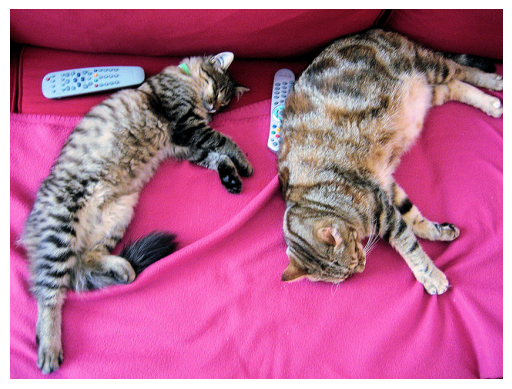

In [20]:
from PIL import Image
import matplotlib.pyplot as plt
import requests

def load_image(url):
    response = requests.get(url, stream=True)
    return Image.open(response.raw)

url = "http://images.cocodataset.org/val2017/000000039769.jpg"

image = load_image(url)
prompt = 'left cat'

plt.imshow(image)
plt.axis('off')
plt.show()

Some model parameters or buffers are not found in the checkpoint:
detr.mask_dino.predictor.resizer.fc.{bias, weight}
detr.mask_dino.predictor.resizer.layer_norm.{bias, weight}
The checkpoint state_dict contains keys that are not used by the model:
  text_encoder.body.model.embeddings.position_ids
  detr.mask_dino.predictor.label_enc.weight


Length of coco_panoptic Categories : 133
Length of pascal_parts_val Categories : 200
Length of coco_2017_train_panoptic_with_sem_seg Categories : 133


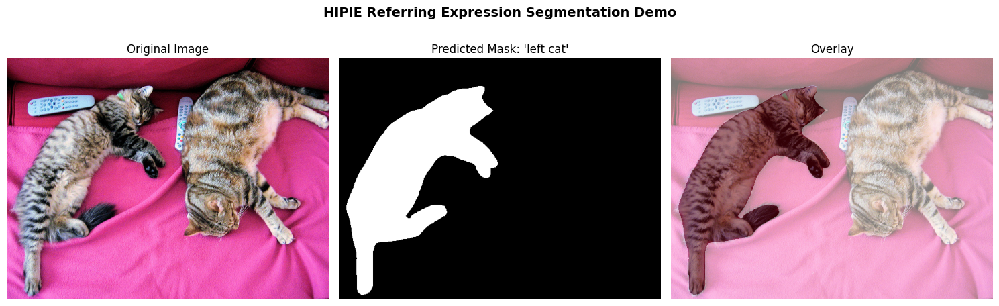

In [23]:
from detectron2.projects.hipie.demo_lib.part_segm_demo import PartSegmDemo


def get_segmentation_mask(image: Image.Image, prompt: str) -> np.ndarray:
    # TODO: Get segmentation mask
    
    image_np = convert_PIL_to_numpy(image, format="BGR")

    out_dict = demo.foward_reference(
        image_np,
        reference_string=prompt,
        part=None,
        use_coarse=False,
    )

    pred_masks = out_dict["final_mask"]  #(N, H, W)
    if isinstance(pred_masks, torch.Tensor):
        pred_masks = pred_masks.cpu().numpy()

    if pred_masks.ndim == 3:
        if pred_masks.shape[0] == 0:
            h, w = image_np.shape[:2]
            return np.zeros((h, w), dtype=bool)
        out = pred_masks[0].astype(bool)
    else:
        out = pred_masks.astype(bool)

    return out
    

# TODO: Define auxiliary parameters


CONFIG_FILE = "projects/HIPIE/configs/training/r50_parts.yaml"
WEIGHT_PATH = "/kaggle/working/HIPIE/pretrained_weights/r50_parts.pth"

demo = PartSegmDemo(
    config_file=CONFIG_FILE,
    weight=WEIGHT_PATH,
)
mask = get_segmentation_mask(image, prompt)


# Visualize result
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image", fontsize=12)
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title(f"Predicted Mask: '{prompt}'", fontsize=12)
axes[1].axis('off')

axes[2].imshow(image)
axes[2].imshow(mask, alpha=0.5, cmap='Reds')
axes[2].set_title("Overlay", fontsize=12)
axes[2].axis('off')

plt.suptitle("HIPIE Referring Expression Segmentation Demo", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. RefCOCO Dataset

The **RefCOCO** dataset contains images paired with textual queries and ground-truth masks.

In [25]:
import os
import gdown
import zipfile
import requests
from pathlib import Path
from tqdm import tqdm


def download_file(url: str, filepath: Path, desc: str = None) -> None:
    """Download a file from URL with progress bar."""
    response = requests.get(url, stream=True)
    total_size = int(response.headers.get('content-length', 0))

    with open(filepath, 'wb') as file, tqdm(
        desc=desc, total=total_size, unit='iB', unit_scale=True, unit_divisor=1024
    ) as pbar:
        for data in response.iter_content(chunk_size=1024):
            size = file.write(data)
            pbar.update(size)


def extract_subset_from_zip(zip_path: Path, extract_dir: Path, max_files: int = 100, 
                            extensions: tuple = ('.jpg', '.jpeg', '.png')) -> None:
    """Extract only first N images from zip to save disk space."""
    extract_dir.mkdir(parents=True, exist_ok=True)
    
    with zipfile.ZipFile(zip_path, 'r') as zf:
        image_files = [f for f in zf.namelist() 
                       if f.lower().endswith(extensions) and not f.startswith('__MACOSX')]
        image_files = sorted(image_files)[:max_files]
        
        print(f"Extracting {len(image_files)} images (of {len(zf.namelist())} total)...")
        for filename in tqdm(image_files, desc="Extracting"):
            zf.extract(filename, extract_dir)
    
    print(f"✓ Extracted {len(image_files)} images to {extract_dir}")


def setup_refcoco_dataset(data_dir: Path = Path("/kaggle/working"), max_train_images: int = 100) -> None:
    """Download and extract RefCOCO dataset with COCO train2014 images."""
    coco_dir = data_dir / "coco"
    coco_dir.mkdir(parents=True, exist_ok=True)
    
    datasets = {
        'train2014': {
            'url': 'http://images.cocodataset.org/zips/train2014.zip',
            'path': coco_dir / 'train2014.zip',
            'limit': max_train_images,
        },
        'refcoco': {
            'gdrive_id': '1r3P1W07uFhAlMm33bD3XwDronj2BZHi9',
            'path': coco_dir / 'refcoco.zip',
            'limit': None,
        }
    }
    
    for name, dataset in datasets.items():
        zip_path = dataset['path']
        extract_dir = zip_path.parent

        if not zip_path.exists() and not (extract_dir / name).exists():
            print(f"\nDownloading {name}...")
            if 'url' in dataset:
                download_file(dataset['url'], zip_path, desc=name)
            else:
                gdown.download(
                    f"https://drive.google.com/uc?id={dataset['gdrive_id']}",
                    str(zip_path),
                    quiet=False
                )

        if zip_path.exists():
            print(f"\nExtracting {name}...")
            limit = dataset.get('limit')
            if limit is not None:
                extract_subset_from_zip(zip_path, extract_dir, max_files=limit)
            else:
                with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                    zip_ref.extractall(extract_dir)
            
            zip_path.unlink()
            print(f"Deleted {zip_path} to free space")

    print("\nDataset setup complete!")

In [34]:
setup_refcoco_dataset(max_train_images=100)

train2014: 100%|██████████| 12.6G/12.6G [04:14<00:00, 53.0MiB/s] 



Extracting train2014...
Extracting 100 images (of 82784 total)...


Extracting: 100%|██████████| 100/100 [00:00<00:00, 2218.32it/s]

✓ Extracted 100 images to /kaggle/working/coco


Deleted /kaggle/working/coco/train2014.zip to free space



Downloading...
From (original): https://drive.google.com/uc?id=1r3P1W07uFhAlMm33bD3XwDronj2BZHi9
From (redirected): https://drive.google.com/uc?id=1r3P1W07uFhAlMm33bD3XwDronj2BZHi9&confirm=t&uuid=41886bc4-2af4-465e-93de-41708f1b8ec9
To: /kaggle/working/coco/refcoco.zip
100%|██████████| 54.0M/54.0M [00:01<00:00, 32.8MB/s]



Extracting refcoco...
Deleted /kaggle/working/coco/refcoco.zip to free space

Dataset setup complete!


## 4. Dataset Class


In [35]:
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple
import json
import pickle


@dataclass
class ReferringItem:
    """Single item from RefCOCO dataset."""
    image_path: Path
    captions: List[str]
    bbox: List[float]
    segmentation: List[List[float]]
    image_id: int = None
    ann_id: int = None


class ReferringDataset:
    """RefCOCO dataset wrapper for referring expression segmentation."""
    
    def __init__(self, data_path: Path, split: str = None, label_type: str = 'google'):
        # TODO: Finish implementation
        # ...
        self.data_path = Path(data_path)
        self.train_img_path = self.data_path / "train2014"
        self.split = split
        self.label_type = label_type
        self.refs, self.bbox_lookup, self.segmentation_lookup = self._load_data()
        print(f"Loaded {len(self.refs)} referring expressions (split={split})")

    def __len__(self) -> int:
        return len(self.refs)

    def __getitem__(self, idx: int) -> ReferringItem:
        # TODO: Finish implementation
        # ...
        if not 0 <= idx < len(self):
            raise IndexError(f"Index {idx} out of bounds for dataset of size {len(self)}")

        ref = self.refs[idx]
        image_id = ref["image_id"]
        ann_id = ref["ann_id"]

        captions = []
        for sent in ref.get("sentences", []):
            captions.append(sent["raw"])

        bbox = self.bbox_lookup.get(ann_id, [])
        segmentation = self.segmentation_lookup.get(ann_id, [])
        image_path = self.get_image_path(image_id)

        return ReferringItem(
            image_path=image_path,
            captions=captions,
            bbox=bbox,
            segmentation=segmentation,
            image_id=image_id,
            ann_id=ann_id,
        )

    def _load_data(self) -> Tuple[List[Dict], Dict, Dict]:
        # TODO: Finish implementation
        # ...
        refs = self._load_annotations(self.data_path / f'refcoco/refs({self.label_type}).p')
        if self.split is not None:
            refs = [ref for ref in refs if ref['split'] == self.split]

        instances = self._load_annotations(self.data_path / "refcoco/instances.json")
        bbox_lookup = {}
        segmentation_lookup = {}
        for ann in instances["annotations"]:
            ann_id = ann["id"]
            bbox_lookup[ann_id] = ann.get("bbox", [])
            segmentation_lookup[ann_id] = ann.get("segmentation", [])
        # segmentation_lookup filled above
        return refs, bbox_lookup, segmentation_lookup

    def get_image_path(self, image_id: int) -> Path:
        return self.train_img_path / f'COCO_train2014_{image_id:012d}.jpg'

    def image_file_exists(self, idx: int) -> bool:
        """True if the COCO train2014 JPEG for this ref exists (needed when only a subset was extracted)."""
        ref = self.refs[idx]
        return self.get_image_path(ref['image_id']).is_file()

    def list_indices_with_images_on_disk(self, max_scan: Optional[int] = None) -> List[int]:
        """Indices whose image file is present under train2014/."""
        n = len(self) if max_scan is None else min(max_scan, len(self))
        return [i for i in range(n) if self.image_file_exists(i)]

    @staticmethod
    def _load_annotations(file_path: Path) -> Any:
        if file_path.suffix == '.json':
            with open(file_path, 'r') as f:
                return json.load(f)
        elif file_path.suffix == '.p':
            with open(file_path, 'rb') as f:
                return pickle.load(f)
        raise ValueError(f"Unsupported file format: {file_path.suffix}")


In [36]:
DATA_PATH = Path('/kaggle/working/coco')
dataset = ReferringDataset(DATA_PATH, split='test')

EXISTING_IMAGE_INDICES = dataset.list_indices_with_images_on_disk()
NUM_SAMPLES = 5

if len(EXISTING_IMAGE_INDICES) == 0:
    raise FileNotFoundError(
        f"No JPEGs found under {dataset.train_img_path}. "
        "Extract train2014 images (or increase extract count) so paths match RefCOCO image_ids."
    )

samples = [dataset[i] for i in EXISTING_IMAGE_INDICES[:NUM_SAMPLES]]

print(f"Dataset size: {len(dataset)} referring expressions")
print(f"Images on disk (matched refs): {len(EXISTING_IMAGE_INDICES)}")
print(f"Using first {len(samples)} samples that have files on disk")

Loaded 5000 referring expressions (split=test)
Dataset size: 5000 referring expressions
Images on disk (matched refs): 4
Using first 4 samples that have files on disk


## 5. Check Performance
One referring phrase per sample (first caption). IoU vs polygon GT;

In [39]:
from typing import List, Tuple
from tqdm.auto import tqdm
from pycocotools import mask as mask_utils


def _iou(pred_bool: np.ndarray, gt_bool: np.ndarray) -> float:
    # TODO: Finish implementation
    # ...
    pred_bool = pred_bool.astype(bool)
    gt_bool = gt_bool.astype(bool)

    inter = np.logical_and(pred_bool, gt_bool).sum()
    union = np.logical_or(pred_bool, gt_bool).sum()

    if union == 0:
        return 0.0
    iou = inter / union
    return float(iou)


def _polygons_to_mask(segmentation, height: int, width: int) -> np.ndarray:
    """COCO polygons -> bin_mask (H, W)."""
    if segmentation is None or len(segmentation) == 0:
        return np.zeros((height, width), dtype=bool)

    rles = mask_utils.frPyObjects(segmentation, height, width)
    decoded = mask_utils.decode(rles)
    if decoded.ndim == 3:
        gt = decoded.any(axis=-1)
    else:
        gt = decoded.astype(bool)
    return gt


def run_hipie_on_refcoco(
    samples: List[ReferringItem],
    caption_index: int = 0,
    pred_threshold: float = 0.5,
) -> List[Tuple[Image.Image, str, np.ndarray, np.ndarray, float]]:
    """For each sample: first caption → HIPIE mask; IoU vs GT polygon."""
    # TODO: Finish implementation
    # ...
    results = []

    for item in tqdm(samples, desc="HIPIE on RefCOCO"):
        image = Image.open(item.image_path).convert("RGB")
        w, h = image.size

        if len(item.captions) == 0:
            continue
        prompt = item.captions[caption_index]

        pred_mask = get_segmentation_mask(image, prompt)

        gt_mask = _polygons_to_mask(item.segmentation, h, w)

        iou_score = _iou(pred_mask, gt_mask)

        results.append((image, prompt, pred_mask, gt_mask, iou_score))

    return results


def _mask_panel(mask_bool, color_fg, color_bg="#0d1117"):
    import matplotlib.colors as mcolors

    h, w = mask_bool.shape
    rgba = np.zeros((h, w, 4), dtype=np.float32)
    m = mask_bool.astype(bool)
    rgb = np.array(mcolors.to_rgb(color_fg))
    rgba[m, :3] = rgb
    rgba[m, 3] = 1.0
    rgba[~m, :3] = np.array(mcolors.to_rgb(color_bg))
    rgba[~m, 3] = 1.0
    return rgba

def _blend_mask_on_image(rgb_uint8, mask_bool, rgb_color, alpha=0.62):
    base = rgb_uint8.astype(np.float32) / 255.0
    c = np.array(rgb_color, dtype=np.float32) / 255.0
    m = mask_bool.astype(bool)
    out = base.copy()
    out[m] = base[m] * (1.0 - alpha) + c * alpha
    return np.clip(out * 255.0, 0, 255).astype(np.uint8)

    
def plot_refcoco_inference_rows(results, max_plots: int = 8):
    COL_PRED = (0, 245, 255)   # cyan
    COL_GT = (80, 255, 120)    # lime
    COL_OVERLAY_PRED = (255, 70, 140)
    COL_OVERLAY_GT = (40, 255, 200)

    for k, (img, prompt, pred, gt, iou_score) in enumerate(results[:max_plots]):
        arr = np.asarray(img)
        if arr.ndim == 2:
            arr = np.stack([arr] * 3, axis=-1)

        fig, axes = plt.subplots(
            1, 4,
            figsize=(17, 4.2),
            gridspec_kw={"wspace": 0.08, "left": 0.02, "right": 0.98, "top": 0.82, "bottom": 0.06},
        )

        titles = ["Input image", "Prediction", "Ground truth", "Overlay + IoU"]
        for ax, title in zip(axes, titles):
            ax.set_title(title, fontsize=11, fontweight="bold", pad=8, color="#1a1a1a")

        axes[0].imshow(arr)
        axes[0].set_facecolor("#f0f2f5")

        axes[1].imshow(_mask_panel(pred, "#00e5ff", "#121826"))
        axes[2].imshow(_mask_panel(gt, "#56ff7a", "#121826"))

        both = _blend_mask_on_image(arr, pred, COL_OVERLAY_PRED, alpha=0.58)
        both = _blend_mask_on_image(both, gt, COL_OVERLAY_GT, alpha=0.52)
        axes[3].imshow(both)

        iou_color = "#0a8f3c" if iou_score >= 0.5 else ("#c97800" if iou_score >= 0.25 else "#c62828")
        axes[3].set_title(
            f"IoU = {iou_score:.3f}",
            fontsize=12,
            fontweight="bold",
            color=iou_color,
            pad=8,
        )
        for ax in axes:
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1.2)
                spine.set_edgecolor("#cfd8dc")

        short = prompt if len(prompt) < 100 else prompt[:97] + "…"
        fig.suptitle(
            short,
            fontsize=11,
            y=0.98,
            wrap=True,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#e3f2fd", edgecolor="#90caf9", linewidth=1),
        )
        plt.show()


HIPIE on RefCOCO:   0%|          | 0/4 [00:00<?, ?it/s]

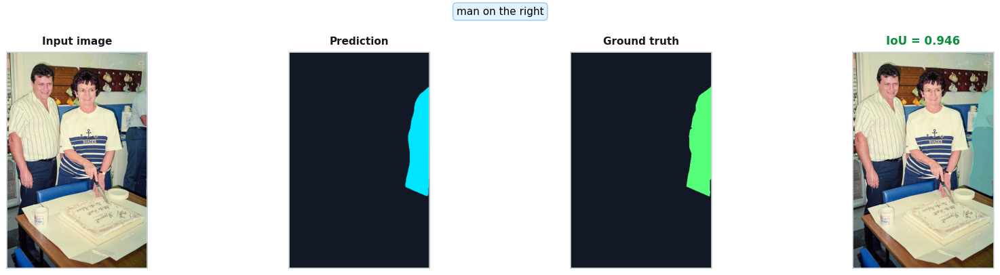

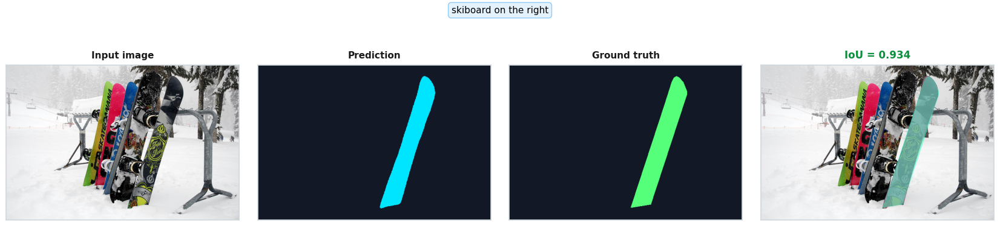

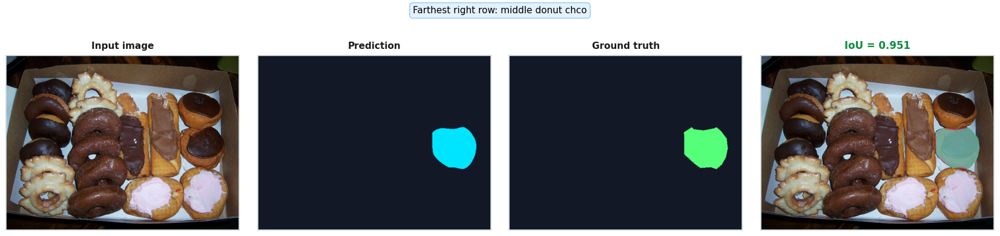

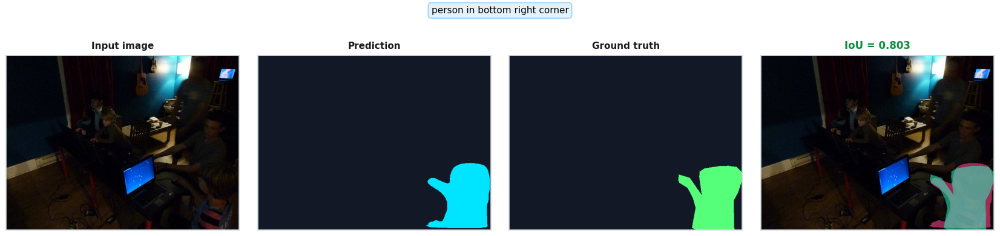

In [40]:
refcoco_results = run_hipie_on_refcoco(samples)
plot_refcoco_inference_rows(refcoco_results)

Everything looks good, right?...

## 6. Negative Prompting
Negative prompts describe objects absent from an image. Since the RefCOCO benchmark lacks such examples, we evaluate model performance using prompts unrelated to the selected image. Specifically, if the cosine similarity between the original and negative prompt is below a threshold (e.g., < 0.5), the prompts are considered unrelated. A more advanced method involves using a language or vision-language model to determine if a prompt refers to an image or not.

In [45]:
import random

NUM_UNRELATED_PROMPTS = 8

_GENERIC_UNRELATED = [
    # You can add more prompts here / change existing ones
    "the red stop sign on the corner",
    "a person wearing a yellow helmet",
    "the tennis racket next to the net",
    "a large white cruise ship",
    "the giraffe behind the fence",
    "a microwave oven on the counter",
    "the motorcycle parked on the street",
    "a slice of pizza on a plate",
    "the traffic light showing green",
    "a snowboard leaning against the wall",
    "the boat floating on the lake"
]


def _seven_unrelated_prompts(
    item: ReferringItem,
    pool_items: List[ReferringItem],
    rng: random.Random = 42,
    n: int = NUM_UNRELATED_PROMPTS,
) -> List[str]:
    """Up to n distinct short captions from other images, then generic fillers."""
    others = [x for x in pool_items if x.image_id != item.image_id]
    rng.shuffle(others)
    prompts: List[str] = []
    for o in others:
        if not o.captions:
            continue
        t = o.captions[0].strip()
        if t and t not in prompts:
            prompts.append(t)
        if len(prompts) >= n:
            return prompts[:n]
    gen = list(_GENERIC_UNRELATED)
    rng.shuffle(gen)
    for t in gen:
        if t not in prompts:
            prompts.append(t)
        if len(prompts) >= n:
            return prompts[:n]
    k = 0
    while len(prompts) < n:
        prompts.append(f"{rng.choice(_GENERIC_UNRELATED)} ({k})")
        k += 1
    return prompts[:n]


def run_hipie_negative_prompts(
    samples: List[ReferringItem],
    dataset: ReferringDataset,
    existing_indices: List[int],
    pred_threshold: float = 0.5,
    seed: int = 42,
) -> List[Tuple[Image.Image, np.ndarray, List[Tuple[str, np.ndarray, float]], str]]:
    """Per sample: GT mask + NUM_UNRELATED_PROMPTS HIPIE masks from unrelated text.

    Returns list of (image, gt_bool, [(prompt, pred_bool, iou), ...×7], true_caption).
    """
    rng = random.Random(seed)
    pool_items = [dataset[i] for i in existing_indices]

    out = []

    for item in tqdm(samples, desc="HIPIE negative prompts"):
        # TODO: Finish implementation
        # ...
        image = Image.open(item.image_path).convert("RGB")
        w, h = image.size

        gt_mask = _polygons_to_mask(item.segmentation, h, w)

        true_caption = item.captions[0] if item.captions else ""

        neg_prompts = _seven_unrelated_prompts(item, pool_items, rng=rng)

        per_prompt = []
        for prompt in neg_prompts:
            # TODO: Finish implementation
            # ...
            pred_mask = get_segmentation_mask(image, prompt)
            iou_score = _iou(pred_mask, gt_mask)
            per_prompt.append((prompt, pred_mask, iou_score))

        out.append((image, gt_mask, per_prompt, true_caption))

    return out


def plot_refcoco_negative_rows(results, max_plots: int = 8):
    pred_colors = ["#00e5ff", "#ff6ec7", "#b388ff", "#69f0ae", "#ffd740", "#ff8a65", "#80d8ff"]

    for row in results[:max_plots]:
        img, gt_bool, triples, true_caption = row
        arr = np.asarray(img)
        if arr.ndim == 2:
            arr = np.stack([arr] * 3, axis=-1)

        ncols = 2 + len(triples)
        fig_w = 2.1 * ncols
        fig, axes = plt.subplots(
            1,
            ncols,
            figsize=(fig_w, 3.9),
            gridspec_kw={"wspace": 0.12, "left": 0.02, "right": 0.98, "top": 0.82, "bottom": 0.18},
        )
        if ncols == 1:
            axes = [axes]

        axes[0].imshow(arr)
        axes[0].set_title("Image", fontsize=11, fontweight="bold", pad=6)
        axes[0].set_facecolor("#f0f2f5")

        _, first_pred, _ = triples[0]
        gt_display = gt_bool
        if gt_display.shape != first_pred.shape:
            gt_display = cv2.resize(
                gt_bool.astype(np.uint8),
                (first_pred.shape[1], first_pred.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            ).astype(bool)

        axes[1].imshow(_mask_panel(gt_display, "#56ff7a", "#121826"))
        axes[1].set_title("GT mask", fontsize=11, fontweight="bold", pad=6)

        for j, (prompt, pred, iou_score) in enumerate(triples):
            ax = axes[2 + j]
            ax.imshow(_mask_panel(pred, pred_colors[j % len(pred_colors)], "#121826"))
            short = (prompt[:42] + "…") if len(prompt) > 43 else prompt
            ax.set_title(f"U{j + 1}\n{short}", fontsize=7, pad=4)
            ax.set_xlabel(f"IoU={iou_score:.2f}", fontsize=8, color="#555")

        for ax in axes:
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1.0)
                spine.set_edgecolor("#cfd8dc")

        st = true_caption if len(true_caption) < 120 else true_caption[:117] + "…"
        fig.suptitle(
            f"GT refers to: {st}",
            fontsize=10,
            y=1.02,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="#e8f5e9", edgecolor="#66bb6a", linewidth=1),
        )
        plt.show()


HIPIE negative prompts:   0%|          | 0/4 [00:00<?, ?it/s]

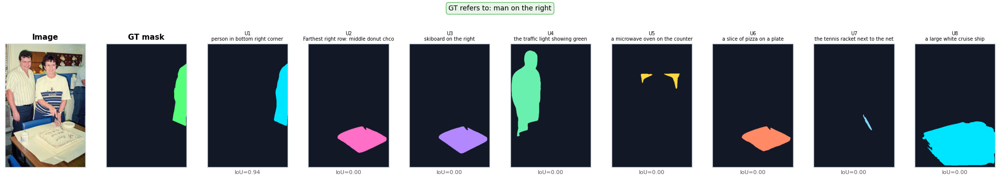

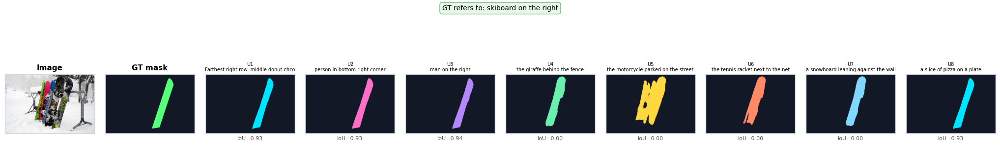

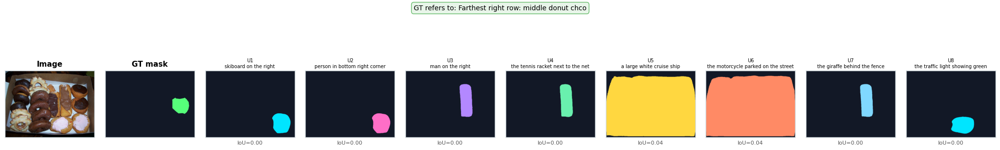

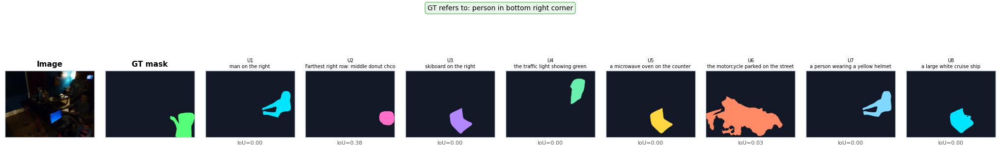

In [46]:
refcoco_neg_results = run_hipie_negative_prompts(samples, dataset, EXISTING_IMAGE_INDICES, seed=123)
plot_refcoco_negative_rows(refcoco_neg_results)

What conclusions can be made?

# **Reasoning Segmentation**

This part of the notebook explores **LISA**, a reasoning segmentation model that combines a large language model (LLaMA in LLaVA) with the SAM decoder to produce segmentation masks from natural-language prompts.

> **Important:** it is recommended to do `Factory reset` at this point

## 1. Environment Setup

### 1.1. Install Dependencies

> **Environment:** run this notebook on **Kaggle** with a T4 GPU to avoid memory issues or version inconsistencies.

# **Referring Expression Segmentation**

## 1. Environment Setup

### 1.1. Install Dependencies

## 1. Environment Setup

### 1.1. Install Dependencies

In [ ]:
!git clone https://github.com/dvlab-research/LISA.git
import os
os.chdir("LISA")

In [ ]:
%%writefile requirements.txt
packaging
sentencepiece
peft==0.4.0
einops==0.4.1
fastapi==0.100.1
gradio==3.39.0
markdown2==2.4.10
openai==0.27.8
opencv_python==4.8.0.74
Pillow==9.4.0
pycocotools==2.0.6
Requests==2.31.0
shortuuid==1.0.11
tqdm==4.64.1

In [ ]:
!pip install -r requirements.txt
!pip install numpy ray uvicorn scipy bitsandbytes
!pip install transformers==4.34
!pip install --force-reinstall "numpy<2"
!python -m pip uninstall -y huggingface_hub
!python -m pip install --no-cache-dir --force-reinstall "huggingface_hub==0.23.4"

### 1.2. Verify Installation

> **Important:** restart the kernel now (`Kernel → Restart & clear cell outputs`) before running the cells below.

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import transformers, huggingface_hub
print("transformers:", transformers.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
from huggingface_hub import split_torch_state_dict_into_shards
print("Installation OK")

transformers: 4.34.0
huggingface_hub: 0.23.4
Installation OK


### 1.3. Compatibility Patches

The cells below apply targeted patches to resolve version-specific incompatibilities between the LISA codebase and the Kaggle runtime.

In [3]:
import os, sys
os.chdir("/kaggle/working/LISA")
if "/kaggle/working/LISA" not in sys.path:
    sys.path.insert(0, "/kaggle/working/LISA")

In [4]:
from transformers import AutoConfig, AutoModelForCausalLM

_orig_cfg_register = AutoConfig.register
def _safe_cfg_register(model_type, config, exist_ok=False):
    if model_type == "llava":
        exist_ok = True
    return _orig_cfg_register(model_type, config, exist_ok=exist_ok)
AutoConfig.register = _safe_cfg_register

_orig_model_register = AutoModelForCausalLM.register
def _safe_model_register(config_class, model_class, exist_ok=False):
    try:
        return _orig_model_register(config_class, model_class, exist_ok=exist_ok)
    except (ValueError, KeyError):
        return None
AutoModelForCausalLM.register = _safe_model_register

In [5]:
import accelerate.big_modeling as bm
import transformers.modeling_utils as mu

_orig_bm_dispatch = bm.dispatch_model

def _safe_dispatch(model, *args, **kwargs):
    if getattr(model, "quantization_method", None) is not None:
        return model
    return _orig_bm_dispatch(model, *args, **kwargs)

bm.dispatch_model = _safe_dispatch
mu.dispatch_model = _safe_dispatch

/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:311: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


In [6]:
import torch
import transformers.models.llama.modeling_llama as llama_mod

_orig_apply_rotary = llama_mod.apply_rotary_pos_emb

def _patched_apply_rotary_pos_emb(q, k, cos, sin, position_ids):
    target = q.device
    cos = cos.to(target)
    sin = sin.to(target)
    if position_ids is not None:
        position_ids = position_ids.to(target)
    return _orig_apply_rotary(q, k, cos, sin, position_ids)

llama_mod.apply_rotary_pos_emb = _patched_apply_rotary_pos_emb
print("All patches applied.")

All patches applied.


### 1.4. Fix Seeds


In [7]:
import os
import random
import numpy as np

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

    import torch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    from transformers import set_seed
    set_seed(seed)
    
    print(f"✅ All random seeds fixed to: {seed}")

seed_everything(42)

2026-05-06 15:12:49.137447: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778080369.646245     812 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778080369.751631     812 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778080370.923198     812 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778080370.923246     812 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778080370.923249     812 computation_placer.cc:177] computation placer alr

✅ All random seeds fixed to: 42


## 2. Load the LISA Model

In [8]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from pprint import pprint
from transformers import AutoTokenizer, BitsAndBytesConfig, CLIPImageProcessor

# TODO: Add all necessary imports here
# ...
from model.LISA import LISAForCausalLM
from model.llava import conversation as conversation_lib
from model.llava.mm_utils import tokenizer_image_token
from model.llava.constants import (
    DEFAULT_IM_END_TOKEN,
    DEFAULT_IM_START_TOKEN,
    DEFAULT_IMAGE_TOKEN,
    IMAGE_TOKEN_INDEX,
)
from model.segment_anything.utils.transforms import ResizeLongestSide


/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:311: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


In [9]:
VERSION = "xinlai/LISA-13B-llama2-v1"

# TODO: Load tokenizer here
# ...
tokenizer = AutoTokenizer.from_pretrained(
    VERSION,
    model_max_length=512,
    padding_side="right",
    use_fast=False,
)

tokenizer.pad_token = tokenizer.unk_token

tokenizer.add_tokens("[SEG]")
seg_token_idx = tokenizer("[SEG]", add_special_tokens=False).input_ids[0]

tokenizer.add_tokens(
    [DEFAULT_IM_START_TOKEN, DEFAULT_IM_END_TOKEN], special_tokens=True
)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


0

In [10]:
# TODO: Load model in 4-bit mode here
# ...
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
)

torch_dtype = torch.bfloat16

model = LISAForCausalLM.from_pretrained(
    VERSION,
    torch_dtype=torch_dtype,
    quantization_config=bnb_config,
    low_cpu_mem_usage=True,
    seg_token_idx=seg_token_idx,
)

model.config.eos_token_id = tokenizer.eos_token_id
model.config.bos_token_id = tokenizer.bos_token_id
model.config.pad_token_id = tokenizer.pad_token_id


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

In [11]:
# TODO: Load vision modules 
# ...
model.get_model().initialize_vision_modules(model.get_model().config)
vision_tower = model.get_model().get_vision_tower()
vision_tower.to(dtype=torch_dtype)

clip_image_processor = CLIPImageProcessor.from_pretrained(model.config.vision_tower)

transform = ResizeLongestSide(1024)

vision_tower = vision_tower.cuda()

model.eval()


LISAForCausalLM(
  (model): LisaModel(
    (embed_tokens): Embedding(32003, 5120, padding_idx=0)
    (layers): ModuleList(
      (0-39): 40 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (k_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (v_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (o_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear4bit(in_features=5120, out_features=13824, bias=False)
          (up_proj): Linear4bit(in_features=5120, out_features=13824, bias=False)
          (down_proj): Linear4bit(in_features=13824, out_features=5120, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm()
        (post_attention_layernorm): LlamaRMSNorm()
      )
  

## 3. Inference Pipeline

In [12]:
# TODO: Define used parameters of the model here
# ...

PARAMETERS = {
    "image_size_clip": 224,
    "image_size_sam": 1024,
    "max_new_tokens": 512,
    "conv_type": "llava_v1",
    "use_mm_start_end": True,
    "sam_pixel_mean": [123.675, 116.28, 103.53],
    "sam_pixel_std":  [58.395, 57.12, 57.375],
}


In [13]:
# TODO: Add here helper functions
# ...

def preprocess_clip(image_rgb, params=PARAMETERS):
    """для CLIP"""
    image_clip = clip_image_processor.preprocess(image_rgb, return_tensors="pt")["pixel_values"][0]
    image_clip = image_clip.unsqueeze(0).cuda().to(torch_dtype)
    return image_clip


def preprocess_sam(image_rgb, params=PARAMETERS):
    """для SAM"""
    image_size_sam = params["image_size_sam"]

    image_sam = transform.apply_image(image_rgb)
    resize_shape = image_sam.shape[:2]

    image_sam = torch.from_numpy(image_sam).permute(2, 0, 1).contiguous().float()

    pixel_mean = torch.tensor(params["sam_pixel_mean"]).view(-1, 1, 1)
    pixel_std = torch.tensor(params["sam_pixel_std"]).view(-1, 1, 1)
    image_sam = (image_sam - pixel_mean) / pixel_std

    h, w = image_sam.shape[-2:]
    pad_h = image_size_sam - h
    pad_w = image_size_sam - w
    image_sam = F.pad(image_sam, (0, pad_w, 0, pad_h))

    image_sam = image_sam.unsqueeze(0).cuda().to(torch_dtype)
    return image_sam, resize_shape


def build_prompt(prompt: str, params=PARAMETERS) -> str:
    
    conv = conversation_lib.conv_templates[params["conv_type"]].copy()
    conv.messages = []

    if params["use_mm_start_end"]:
        image_token = DEFAULT_IM_START_TOKEN + DEFAULT_IMAGE_TOKEN + DEFAULT_IM_END_TOKEN
    else:
        image_token = DEFAULT_IMAGE_TOKEN

    user_message = image_token + "\n" + prompt
    conv.append_message(conv.roles[0], user_message)
    conv.append_message(conv.roles[1], None)
    return conv.get_prompt()


@torch.no_grad()
def run_inference(prompt, image_path, params=PARAMETERS):
    # TODO: Finish implementation
    # ...

    image_bgr = cv2.imread(image_path)
    image_rgb = image_bgr[..., ::-1]
    original_size = image_rgb.shape[:2]

    image_clip = preprocess_clip(image_rgb, params)
    image_sam, resize_shape = preprocess_sam(image_rgb, params)

    full_prompt = build_prompt(prompt, params)
    input_ids = tokenizer_image_token(full_prompt, tokenizer, return_tensors="pt")
    input_ids = input_ids.unsqueeze(0).cuda()

    output_ids, pred_masks = model.evaluate(
        image_clip,
        image_sam,
        input_ids,
        [resize_shape],
        [original_size],
        max_new_tokens=params["max_new_tokens"],
        tokenizer=tokenizer,
    )

    output_ids = output_ids[0][output_ids[0] != IMAGE_TOKEN_INDEX]
    text_output = tokenizer.decode(output_ids, skip_special_tokens=False)

    return text_output, pred_masks


In [14]:
def overlay_mask(image_np, pred_mask, color=(255, 0, 0), alpha=0.5):
    mask = pred_mask.detach().cpu().numpy()[0] > 0
    overlay = image_np.copy()
    overlay[mask] = (
        image_np * (1 - alpha)
        + mask[:, :, None].astype(np.uint8) * np.array(color) * alpha
    )[mask]
    return overlay


def show_segmentation(image_path, pred_masks, title=""):
    image_np = cv2.imread(image_path)[..., ::-1]
    fig, axes = plt.subplots(1, max(len(pred_masks), 1) + 1, figsize=(6 * (len(pred_masks) + 1), 5))
    if not isinstance(axes, np.ndarray):
        axes = [axes]
    axes[0].imshow(image_np)
    axes[0].set_title("Original")
    axes[0].axis("off")
    for i, pm in enumerate(pred_masks):
        axes[i + 1].imshow(overlay_mask(image_np, pm))
        axes[i + 1].set_title(f"Mask {i}")
        axes[i + 1].axis("off")
    if title:
        fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

### 3.1. Text-Only Question Answering

When the prompt does **not** ask for a segmentation mask, LISA behaves like a standard VQA model and returns text only.

In [15]:
text_output, pred_masks = run_inference(
    prompt="Who was the president of the US in this image?",
    image_path="imgs/obama.jpg",
)
print("Model response:", text_output.split("ASSISTANT: ")[-1] if "ASSISTANT:" in text_output else text_output)
print("Masks returned:", len(pred_masks), "— shape:", [m.shape for m in pred_masks])

/usr/local/lib/python3.12/dist-packages/transformers/generation/utils.py:1421: UserWarning: You have modified the pretrained model configuration to control generation. This is a deprecated strategy to control generation and will be removed soon, in a future version. Please use and modify the model generation configuration (see https://huggingface.co/docs/transformers/generation_strategies#default-text-generation-configuration )
  warnings.warn(


Model response: The President of the US in this image is President Obama.</s>
Masks returned: 1 — shape: [torch.Size([0, 409, 594])]


### 3.2. Segmentation via Textual Prompt

Appending *"Please output segmentation mask"* triggers the model to produce a `[SEG]` token whose hidden state is forwarded to the SAM decoder.

Model response: Sure, [SEG]  .</s>


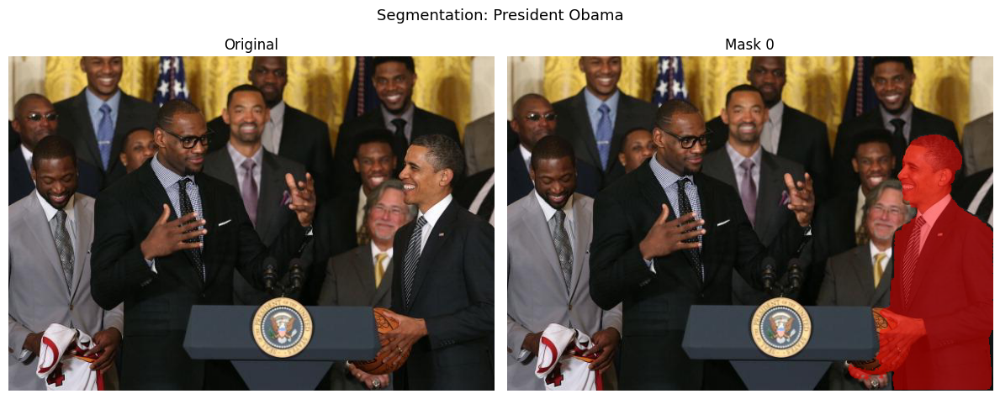

In [16]:
text_output, pred_masks = run_inference(
    prompt="Who was the president of the US in this image? Please output segmentation mask",
    image_path="imgs/obama.jpg",
)
print("Model response:", text_output.split("ASSISTANT: ")[-1] if "ASSISTANT:" in text_output else text_output)
show_segmentation("imgs/obama.jpg", pred_masks, title="Segmentation: President Obama")

## 4. ReasonSeg Dataset

The **ReasonSeg** dataset contains images paired with complex reasoning-based segmentation queries and ground-truth masks.

In [17]:
!find /kaggle/input -maxdepth 6 -type d | grep -Ei "reason|reasonseg|reason_seg|/train$|/val$|/test$" | sort | head -n 300


/kaggle/input/datasets/sashadance/reasonseg
/kaggle/input/datasets/sashadance/reasonseg/test
/kaggle/input/datasets/sashadance/reasonseg/test/test
/kaggle/input/datasets/sashadance/reasonseg/train
/kaggle/input/datasets/sashadance/reasonseg/train/train
/kaggle/input/datasets/sashadance/reasonseg/val
/kaggle/input/datasets/sashadance/reasonseg/val/val


In [18]:
!mkdir -p /kaggle/working/LISA/data/reason_seg/ReasonSeg/{train,val,test}


In [19]:
!cp -r /kaggle/input/datasets/sashadance/reasonseg/train/train/* /kaggle/working/LISA/data/reason_seg/ReasonSeg/train/
!cp -r /kaggle/input/datasets/sashadance/reasonseg/val/val/*     /kaggle/working/LISA/data/reason_seg/ReasonSeg/val/
!cp -r /kaggle/input/datasets/sashadance/reasonseg/test/test/*   /kaggle/working/LISA/data/reason_seg/ReasonSeg/test/


In [20]:
# TODO: Define ReasonSeg Dataset here
# ...
from utils.dataset import ValDataset

BASE_DIR = "/kaggle/working/LISA/data"
IMAGE_SIZE = 1024

val_dataset = ValDataset(
    base_image_dir=BASE_DIR,
    tokenizer=tokenizer,
    vision_tower=model.config.vision_tower,
    val_dataset="ReasonSeg|val",
    image_size=IMAGE_SIZE,
)

train_dataset = ValDataset(
    base_image_dir=BASE_DIR,
    tokenizer=tokenizer,
    vision_tower=model.config.vision_tower,
    val_dataset="ReasonSeg|train",
    image_size=IMAGE_SIZE,
)

test_dataset = ValDataset(
    base_image_dir=BASE_DIR,
    tokenizer=tokenizer,
    vision_tower=model.config.vision_tower,
    val_dataset="ReasonSeg|test",
    image_size=IMAGE_SIZE,
)

print(f"Training samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")


Training samples: 239, Validation samples: 200, Test samples: 779


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [21]:
def make_val_dataset_deterministic(val_dataset):
    if getattr(val_dataset, "data_type", None) == "reason_seg":
        val_dataset.images = sorted(val_dataset.images)
    return val_dataset

val_dataset = make_val_dataset_deterministic(val_dataset)

In [22]:
# TODO: Add here helper functions if needed
# ...


@torch.no_grad()
def infer_on_dataset(dataset, ind, params=PARAMETERS):
    # TODO: Finish implementation
    # ...

    item = dataset[ind]
    image_path = item[0]
    conversations = item[3]

    results = []
    for prompt in conversations:
        p = str(prompt)
        # дублировние убираем
        p = p.replace("<image>", "").replace("<im_start>", "").replace("<im_end>", "").strip()

        text_out, pred_masks = run_inference(p, image_path, params=params)
        results.append((text_out, pred_masks))

    return results


### 4.1. Exploring Dataset Samples

Sample 1 — Sure, the segmentation result is [SEG]  .</s>


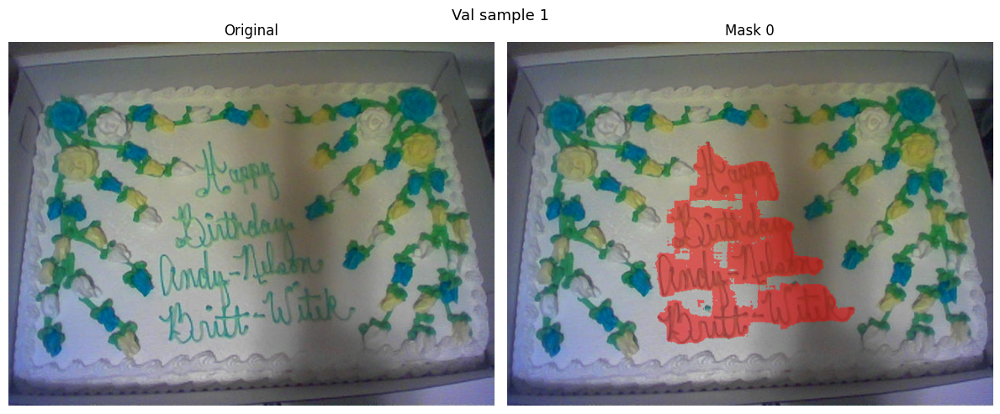

Sample 30 — Sure, it is [SEG]  .</s>


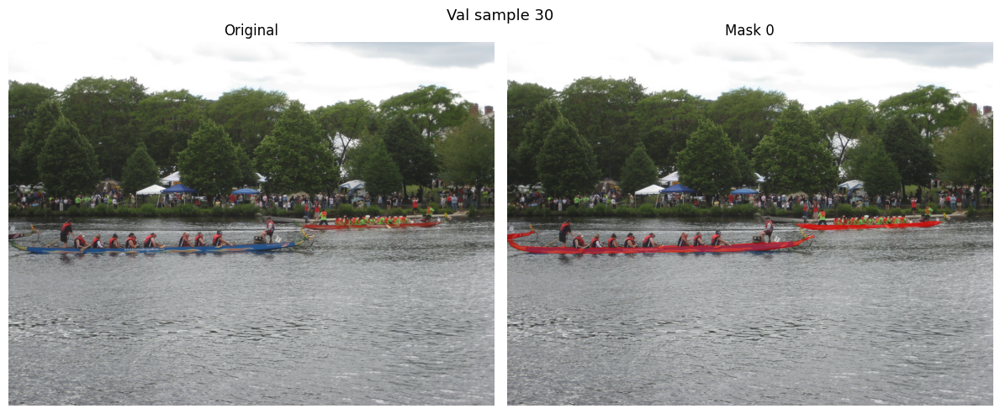

In [23]:
for ind in [1, 30]:
    results = infer_on_dataset(val_dataset, ind)
    image_path, *_ = val_dataset[ind]
    for text_out, pred_masks in results:
        response = text_out.split("ASSISTANT: ")[-1] if "ASSISTANT:" in text_out else text_out
        print(f"Sample {ind} — {response}")
        show_segmentation(image_path, pred_masks, title=f"Val sample {ind}")

## 5. `[SEG]` Token

**Paper reference:** *"Reasoning to Attend: Try to Understand How \<SEG\> Token Works"*

When LISA generates the `[SEG]` token, its hidden state is projected into the SAM prompt space.
The same projection can be applied to the 256 image-token hidden states that the LLM produces for the CLIP patches.
Computing the dot-product similarity between the projected `[SEG]` embedding and the projected image-patch embeddings reveals
**which spatial regions the `[SEG]` token "attends to"** in the language model's representation space.


In [24]:
# TODO: Add here helper functions if needed
# ...

def clean_prompt_text(text):
    txt = str(text)
    txt = txt.replace("<image>", "")
    txt = txt.replace("<im_start>", "")
    txt = txt.replace("<im_end>", "")
    txt = txt.replace("USER:", "")
    txt = txt.replace("ASSISTANT:", "")
    txt = txt.strip()
    return txt

def get_user_prompt(x):
    txt = str(x)

    if "###Human:" in txt:
        txt = txt.split("###Human:", 1)[1]

    if "###Assistant:" in txt:
        txt = txt.split("###Assistant:", 1)[0]

    # служебные токены
    txt = txt.replace("<image>", "")
    txt = txt.replace("<im_start>", "")
    txt = txt.replace("<im_end>", "")
    txt = txt.replace("###", "")

    txt = " ".join(txt.split()).strip()
    return txt



def make_full_ids(input_ids, output_ids):
    # input_ids: [1, L1], output_ids: [1, L2]
    out_ids = output_ids[0]
    out_ids = out_ids[out_ids != IMAGE_TOKEN_INDEX]  # важно
    full_ids = torch.cat([input_ids[0], out_ids], dim=0).unsqueeze(0)
    return full_ids


def get_img_emb(last_hid, input_ids, n_patches=256):
    img_idx_all = (input_ids[0] == IMAGE_TOKEN_INDEX).nonzero(as_tuple=True)[0]
    if len(img_idx_all) == 0:
        return None

    img_idx = img_idx_all[0].item()
    img_emb = last_hid[img_idx:img_idx + n_patches]
    return img_emb


def make_overlay(image_rgb, scr_2d):
    scr = (scr_2d - scr_2d.min()) / (scr_2d.max() - scr_2d.min() + 1e-8)
    h, w = image_rgb.shape[:2]
    scr = cv2.resize(scr, (w, h), interpolation=cv2.INTER_CUBIC)

    heat = (plt.cm.jet(scr)[:, :, :3] * 255).astype(np.uint8)
    over = (0.5 * image_rgb + 0.5 * heat).astype(np.uint8)
    return over

def square_pad(img):
    if isinstance(img, torch.Tensor):
        img = img.detach().cpu().numpy()

    h, w = img.shape[:2]
    side = max(h, w)

    if img.ndim == 2:
        out = np.zeros((side, side), dtype=img.dtype)
        out[:h, :w] = img
    else:
        out = np.zeros((side, side, img.shape[2]), dtype=img.dtype)
        out[:h, :w] = img

    return out


@torch.no_grad()
def compute_seg_similarity(prompt, image_path, params=PARAMETERS):
    # TODO: Finish implementation
    # ...
    # 1 image
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        raise ValueError(f"Cannot read image: {image_path}")
    image_rgb = image_bgr[..., ::-1]
    orig_size = image_rgb.shape[:2]

    # 2 preprocess
    image_clip = preprocess_clip(image_rgb, params)
    image_sam, resize_shape = preprocess_sam(image_rgb, params)

    # 3 prompt
    prompt = get_user_prompt(prompt)
    full_prompt = build_prompt(prompt, params)
    input_ids = tokenizer_image_token(full_prompt, tokenizer, return_tensors="pt").unsqueeze(0).cuda()

    # 4  generation
    output_ids, pred_masks = model.evaluate(
        image_clip,
        image_sam,
        input_ids,
        [resize_shape],
        [orig_size],
        max_new_tokens=params["max_new_tokens"],
        tokenizer=tokenizer,
    )

    # 5 forward 
    full_ids = make_full_ids(input_ids, output_ids)
    out = model(
        input_ids=full_ids,
        images=image_clip,
        attention_mask=torch.ones_like(full_ids),
        past_key_values=None,
        output_hidden_states=True,
        return_dict=True,
    )
    last_hid = out.hidden_states[-1]

    # 6 seg emb
    seg_idx_all = (full_ids[0] == seg_token_idx).nonzero(as_tuple=True)[0]
    if len(seg_idx_all) == 0:
        h, w = image_rgb.shape[:2]
        empty = np.zeros((h, w, 3), dtype=np.uint8)
        return empty, pred_masks

    seg_idx = seg_idx_all[-1].item()  # берем последний [SEG]
    seg_emb = last_hid[seg_idx]

    # 7 image patch emb
    
    img_emb = get_img_emb(last_hid, input_ids, n_patches=256)
    # if img_emb is None:
    #     h, w = image_rgb.shape[:2]
    #     empty = np.zeros((h, w, 3), dtype=np.uint8)
    #     return empty, pred_masks

    # 8 projection + similarity
    proj = model.model.text_hidden_fcs[0]
    seg_emb = proj(seg_emb.unsqueeze(0))
    img_emb = proj(img_emb)

    scr = F.cosine_similarity(seg_emb, img_emb, dim=-1)
    scr = scr.float().cpu().numpy().reshape(16, 16)

    # 9 overlay
    over = make_overlay(image_rgb, scr)
    return over, pred_masks


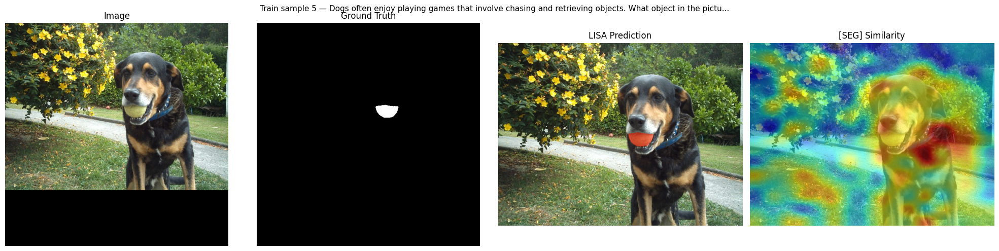

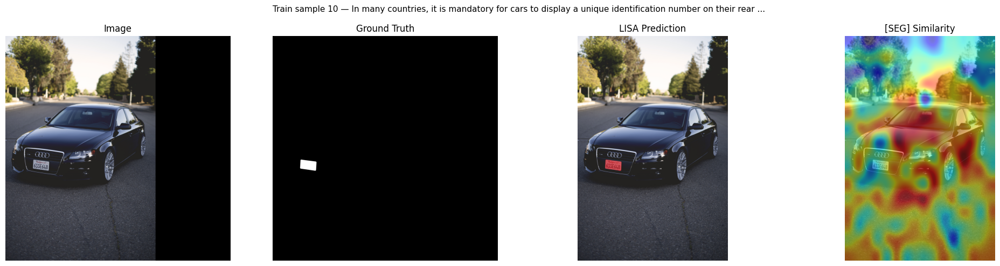

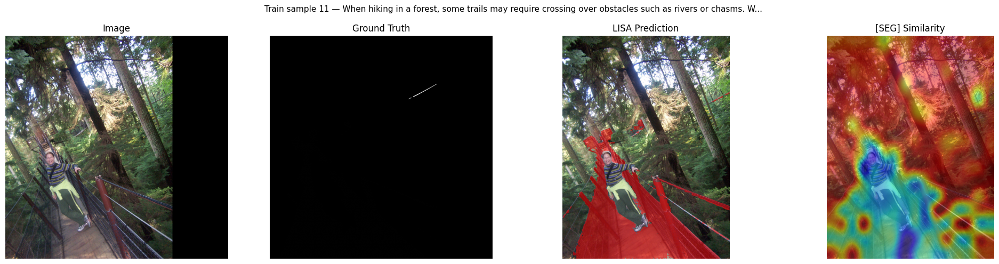

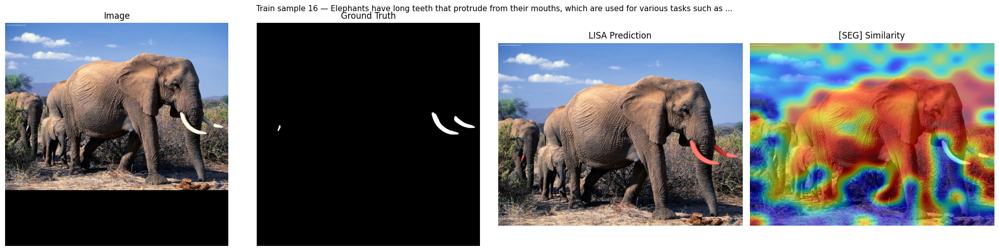

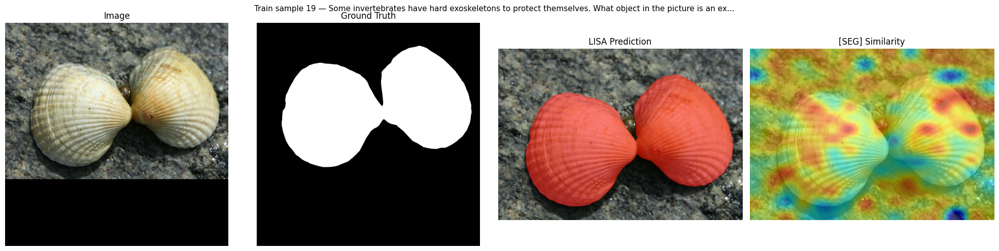

In [25]:
sample_indices = [5, 10, 11, 16, 19]

for ind in sample_indices:
    # TODO: Finish implementation
    # ...
    item = train_dataset[ind]
    image_path = item[0]
    conversations = item[3]
    masks = item[4]

    image_bgr = cv2.imread(image_path)
    image_np = image_bgr[..., ::-1]

    prompt = get_user_prompt(conversations[0])

    similarity_overlay, pred_masks = compute_seg_similarity(prompt=prompt,image_path=image_path)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(square_pad(image_np))
    axes[0].set_title("Image")
    axes[0].axis("off")

    axes[1].imshow(square_pad(masks[0]), cmap="gray")
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    if pred_masks and pred_masks[0].numel() > 0:
        axes[2].imshow(overlay_mask(image_np, pred_masks[0]))
        axes[2].set_title("LISA Prediction")
        axes[2].axis("off")
    else:
        axes[2].set_visible(False)

    axes[3].imshow(similarity_overlay)
    axes[3].set_title("[SEG] Similarity")
    axes[3].axis("off")

    fig.suptitle(f"Train sample {ind} — {prompt[:100]}...", fontsize=11)
    plt.tight_layout()
    plt.show()

## 6. **Layer-wise Probing** — When Does Spatial Grounding Emerge?


**Paper reference:** *Belrose et al., "Eliciting Latent Predictions from Transformers with the Tuned Lens", NeurIPS 2023.*

The *logit lens* technique projects intermediate layer representations into the output vocabulary to observe when a prediction crystallises.
In LISA the analogous question is: **at which transformer layer does the `[SEG]` token's hidden state already encode enough spatial information to produce a correct segmentation mask?**

To answer this, we project the `[SEG]` representation at *every* layer through `text_hidden_fcs` (trained only on the last layer) and feed the resulting 256-d vector to the frozen SAM decoder.

**Task.**
1. Run a full forward pass with `output_hidden_states=True` to obtain the `[SEG]` hidden state at all 40 LLaMA layers.
2. For each layer, project through `text_hidden_fcs`, then run the SAM decoder to obtain a mask.
3. Compute IoU of every layer's mask against the ground-truth.
4. Plot **IoU vs. layer index** and show masks at all layers.
5. *At which depth does grounding emerge? Is the transition gradual or abrupt?*

In [34]:
from utils.utils import intersectionAndUnionGPU

def calc_iou_seg(mask_pred, mask_gt) -> float:
    if isinstance(mask_pred, torch.Tensor):
        mask_pred = mask_pred.detach().cpu().numpy()
    if isinstance(mask_gt, torch.Tensor):
        mask_gt = mask_gt.detach().cpu().numpy()

    mask_pred = np.asarray(mask_pred)
    mask_gt = np.asarray(mask_gt)

    while mask_pred.ndim > 2:
        mask_pred = mask_pred[0]
    while mask_gt.ndim > 2:
        mask_gt = mask_gt[0]

    pred_bool = mask_pred > 0

    if pred_bool.shape != mask_gt.shape:
        pred_bool = cv2.resize(
            pred_bool.astype(np.uint8),
            (mask_gt.shape[1], mask_gt.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        ).astype(bool)

    gt_bool = mask_gt == 1
    valid = mask_gt != 255

    inter = np.logical_and(pred_bool, gt_bool)
    inter = np.logical_and(inter, valid).sum()

    union = np.logical_or(pred_bool, gt_bool)
    union = np.logical_and(union, valid).sum()

    return float(inter / union) if union > 0 else 0.0


In [35]:
def to_np2d(x):
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().numpy()
    x = np.asarray(x)
    while x.ndim > 2:
        x = x[0]
    return x


def add_seg_text(prompt):
    seg_txt = "Please output segmentation mask"
    if seg_txt.lower() not in prompt.lower():
        return prompt + " " + seg_txt
    return prompt

def get_proj_mlp(model_obj):
    return model_obj.get_model().text_hidden_fcs[0]


def strip_img_tokens(text):
    txt = str(text)
    txt = txt.replace(DEFAULT_IMAGE_TOKEN, "")
    txt = txt.replace(DEFAULT_IM_START_TOKEN, "")
    txt = txt.replace(DEFAULT_IM_END_TOKEN, "")
    txt = txt.strip("\n").strip()
    return txt


def make_batch_lisa(text, image_path, params=PARAMETERS, add_seg=True):
    image_bgr = cv2.imread(image_path)
    image_rgb = image_bgr[..., ::-1]
    orig_size = image_rgb.shape[:2]

    image_clip = preprocess_clip(image_rgb, params)
    image_sam, resize_hw = preprocess_sam(image_rgb, params)

    prompt = strip_img_tokens(text)
    if add_seg:
        prompt = add_seg_text(prompt)

    full_prompt = build_prompt(prompt, params)
    ids = tokenizer_image_token(full_prompt, tokenizer, return_tensors="pt")
    ids = ids.unsqueeze(0).cuda()

    return {
        "image_clip": image_clip,
        "image_sam": image_sam,
        "input_ids": ids,
        "resize_list": [resize_hw],
        "orig_list": [orig_size],
    }


def decode_emb_to_mask(seg_emb, image_embs, resize_hw, orig_hw):
    vm = model.get_model().visual_model

    if isinstance(seg_emb, torch.Tensor) and seg_emb.ndim == 1:
        seg_emb = seg_emb.unsqueeze(0)

    sparse = seg_emb.unsqueeze(1)  # (B, 1, 256)

    dense = vm.prompt_encoder.no_mask_embed.weight
    dense = dense.reshape(1, -1, 1, 1).expand(sparse.shape[0], -1, 64, 64)

    low_res, _ = vm.mask_decoder(
        image_embeddings=image_embs,
        image_pe=vm.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse,
        dense_prompt_embeddings=dense,
        multimask_output=False,
    )

    pred = vm.postprocess_masks(
        low_res,
        input_size=resize_hw,
        original_size=orig_hw,
    )
    return pred[:, 0]


def square_pad(img):
    if isinstance(img, torch.Tensor):
        img = img.detach().cpu().numpy()
    img = np.asarray(img)

    h, w = img.shape[:2]
    side = max(h, w)

    if img.ndim == 2:
        out = np.zeros((side, side), dtype=img.dtype)
        out[:h, :w] = img
    else:
        out = np.zeros((side, side, img.shape[2]), dtype=img.dtype)
        out[:h, :w] = img

    return out


In [36]:
@torch.no_grad()
def probe_layers_seg(dataset, idx, save_all_masks=False):
    item = dataset[idx]
    image_path = item[0]
    text = item[3]
    gt_mask = item[4]

    if isinstance(text, (list, tuple)):
        text = text[0]

    batch = make_batch_lisa(text, image_path, params=PARAMETERS, add_seg=True)

    # 1) Первый generate: понять шаг, на котором появился [SEG]
    out1 = model.generate(
        images=batch["image_clip"],
        input_ids=batch["input_ids"],
        max_new_tokens=256,
        num_beams=1,
        do_sample=False,
        return_dict_in_generate=True,
    )

    prompt_len = batch["input_ids"].shape[1]
    gen_ids = out1.sequences[0, prompt_len:].tolist()

    if seg_token_idx not in gen_ids:
        print(f"  [SEG] не был сгенерирован для sample {idx}")
        return None

    seg_step = gen_ids.index(seg_token_idx)

    core = model.get_model()
    layers = core.layers
    norm_last = core.norm
    proj = get_proj_mlp(model)

    n_layers = len(layers)
    layer_h = [None] * n_layers
    step_idx = [0] * n_layers

    def make_hook(layer_idx):
        def hook_fn(module, inp, out):
            hs = out[0] if isinstance(out, tuple) else out
            cur = step_idx[layer_idx]

            # на этом шаге hidden(last token) предсказывает следующий токен
            if cur == seg_step:
                layer_h[layer_idx] = hs[:, -1:, :].detach().clone()

            step_idx[layer_idx] += 1

        return hook_fn

    hooks = [layer.register_forward_hook(make_hook(i)) for i, layer in enumerate(layers)]

    # 2) Второй generate: hooks собирают hidden всех слоев
    try:
        _ = model.generate(
            images=batch["image_clip"],
            input_ids=batch["input_ids"],
            max_new_tokens=256,
            num_beams=1,
            do_sample=False,
            return_dict_in_generate=True,
        )
    finally:
        for h in hooks:
            h.remove()

    miss = [i for i, x in enumerate(layer_h) if x is None]
    if len(miss) > 0:
        raise RuntimeError(f"Не удалось снять hidden для слоёв: {miss}")

    image_embs = model.get_visual_embs(batch["image_sam"])

    iou_list = [0.0] * n_layers
    mask_map = {} if save_all_masks else None

    for layer_idx, h in enumerate(layer_h):
        # h: [1, 1, hidden]
        seg_h = h[0]               # [1, hidden]
        seg_h = norm_last(seg_h)   # как в LLaMA перед lm_head
        seg_emb = proj(seg_h.to(torch_dtype))  # [1, 256]

        pred = decode_emb_to_mask(
            seg_emb,
            image_embs,
            batch["resize_list"][0],
            batch["orig_list"][0],
        )  # [1, H, W]

        iou_list[layer_idx] = calc_iou_seg(pred, gt_mask)

        if save_all_masks:
            m = (pred.detach().cpu().numpy() > 0).astype(np.uint8)
            while m.ndim > 2:
                m = m[0]
            mask_map[layer_idx] = m

    torch.cuda.empty_cache()

    return {
        "ious": iou_list,
        "layer_masks": mask_map,
        "gt_mask": gt_mask,
        "image_path": image_path,
        "num_layers": n_layers,
        "conversations": [text],
        "seg_step": seg_step,
    }


In [37]:
def baseline_iou_seg(dataset, idx, gt_mask):
    item = dataset[idx]
    image_path = item[0]
    text = item[3]

    if isinstance(text, (list, tuple)):
        text = text[0]

    prompt = strip_img_tokens(str(text))
    prompt = add_seg_text(prompt)

    _, pred_masks = run_inference(prompt, image_path)

    gt_np = to_np2d(gt_mask)

    if len(pred_masks) == 0 or pred_masks[0].numel() == 0:
        base_mask = np.zeros_like(gt_np, dtype=bool)
        return 0.0, base_mask

    base_logits = pred_masks[0].detach().cpu().numpy()
    while base_logits.ndim > 2:
        base_logits = base_logits[0]

    base_mask = base_logits > 0

    if base_mask.shape != gt_np.shape:
        base_mask = cv2.resize(
            base_mask.astype(np.uint8),
            (gt_np.shape[1], gt_np.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        ).astype(bool)

    base_iou = calc_iou_seg(base_mask, gt_np)
    return base_iou, base_mask


def draw_iou_curve(iou_list, base_iou, sample_idx, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 4))

    n = len(iou_list)
    x = range(n)

    ax.plot(
        x, iou_list,
        color="#2196F3", linewidth=2, marker="o", markersize=4,
        label="Layer-wise probing",
    )

    ax.axhline(
        y=base_iou,
        color="#F44336", linestyle="--", linewidth=2,
        label=f"LISA baseline ({base_iou:.3f})",
    )

    best_idx = int(np.argmax(iou_list))
    ax.scatter(
        [best_idx], [iou_list[best_idx]],
        color="#4CAF50", s=150, zorder=5,
        label=f"Best: Layer {best_idx} ({iou_list[best_idx]:.3f})",
    )

    ax.scatter(
        [n - 1], [iou_list[-1]],
        color="#FF9800", s=100, zorder=5, marker="s",
        label=f"Final layer ({iou_list[-1]:.3f})",
    )

    ax.set_xlabel("Layer Index", fontsize=11)
    ax.set_ylabel("IoU", fontsize=11)
    ax.set_title(
        f"Sample {sample_idx} — Segmentation IoU Across LLM Layers",
        fontsize=12, fontweight="bold",
    )
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(0, 1.05)
    return ax


def draw_masks_grid(res, image_np, gt_mask, base_mask, base_iou, sample_idx):
    mask_map = res["layer_masks"]
    iou_list = res["ious"]
    n_layers = res["num_layers"]
    gt_np = to_np2d(gt_mask)

    n_cols = 8
    n_rows = int(np.ceil((n_layers + 3) / n_cols))

    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2.5))
    axs = axs.flatten()

    for ax in axs:
        ax.axis("off")

    axs[0].imshow(square_pad(image_np))
    axs[0].set_title("Input Image", fontsize=9, fontweight="bold")

    axs[1].imshow(square_pad(gt_np == 1), cmap="gray")
    axs[1].set_title("Ground Truth", fontsize=9, fontweight="bold")

    axs[2].imshow(square_pad(base_mask), cmap="gray")
    axs[2].set_title(
        f"LISA Baseline\nIoU={base_iou:.3f}",
        fontsize=9, fontweight="bold", color="#F44336",
    )

    best_idx = int(np.argmax(iou_list))

    for i, layer_idx in enumerate(sorted(mask_map.keys())):
        ax_idx = i + 3
        if ax_idx >= len(axs):
            break

        m = mask_map[layer_idx]
        scr = iou_list[layer_idx]

        axs[ax_idx].imshow(square_pad(m), cmap="gray")

        if layer_idx == best_idx:
            color = "#4CAF50"
            title = f"L{layer_idx} *\nIoU={scr:.3f}"
        elif layer_idx == n_layers - 1:
            color = "#FF9800"
            title = f"L{layer_idx} final\nIoU={scr:.3f}"
        else:
            color = "black"
            title = f"Layer {layer_idx}\nIoU={scr:.3f}"

        axs[ax_idx].set_title(title, fontsize=8, color=color)

    fig.suptitle(
        f"Sample {sample_idx} — Layer-wise Mask Predictions",
        fontsize=14, fontweight="bold", y=1.02,
    )
    plt.tight_layout()
    return fig



Analyzing Sample 10
  Prompt: A chat between a curious human and an artificial intelligence assistant. The ass...
  Number of layers: 40
  LISA baseline IoU: 0.7341
  Final layer IoU:   0.5238
  Best layer: 15 with IoU=0.7216


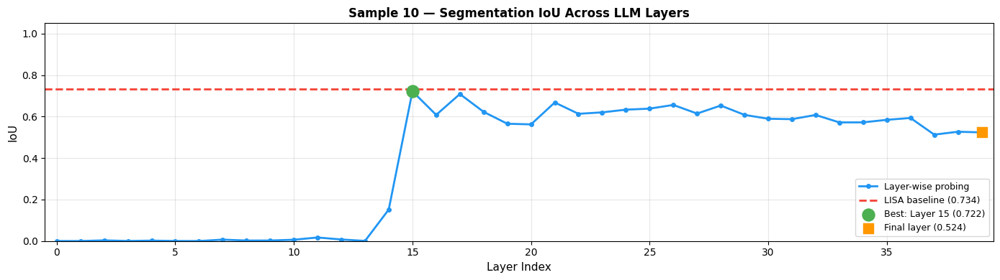

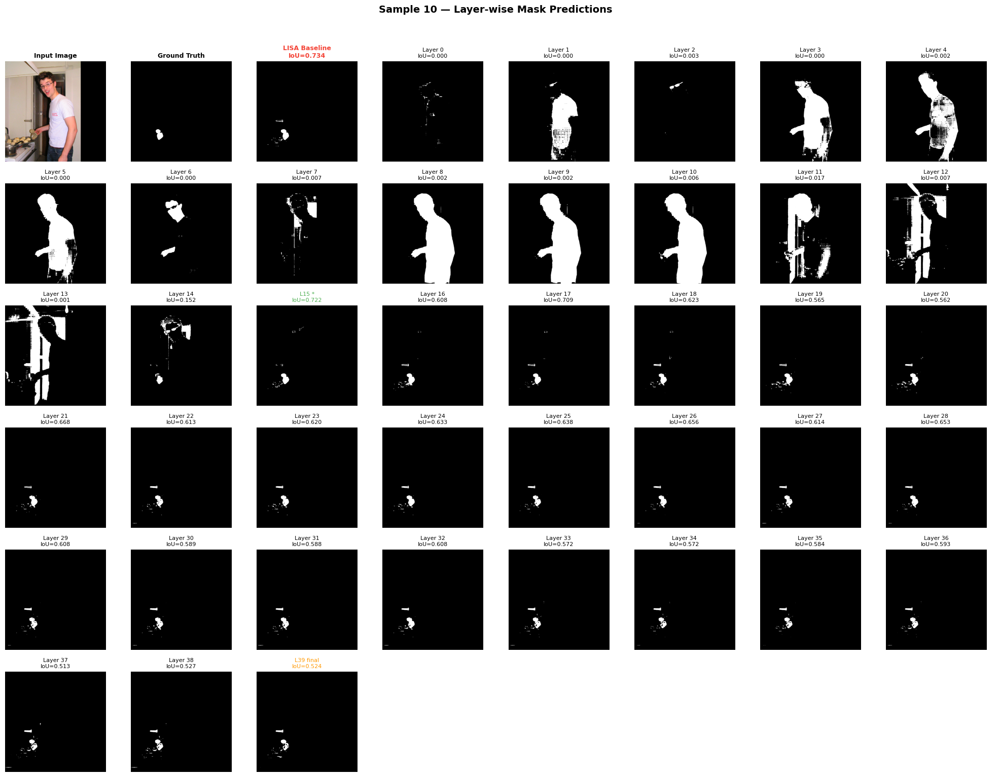


Analyzing Sample 20
  Prompt: A chat between a curious human and an artificial intelligence assistant. The ass...
  Number of layers: 40
  LISA baseline IoU: 0.0002
  Final layer IoU:   0.0000
  Best layer: 16 with IoU=0.8348


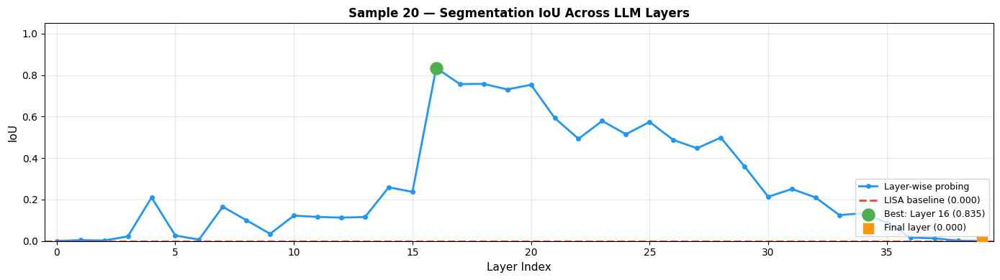

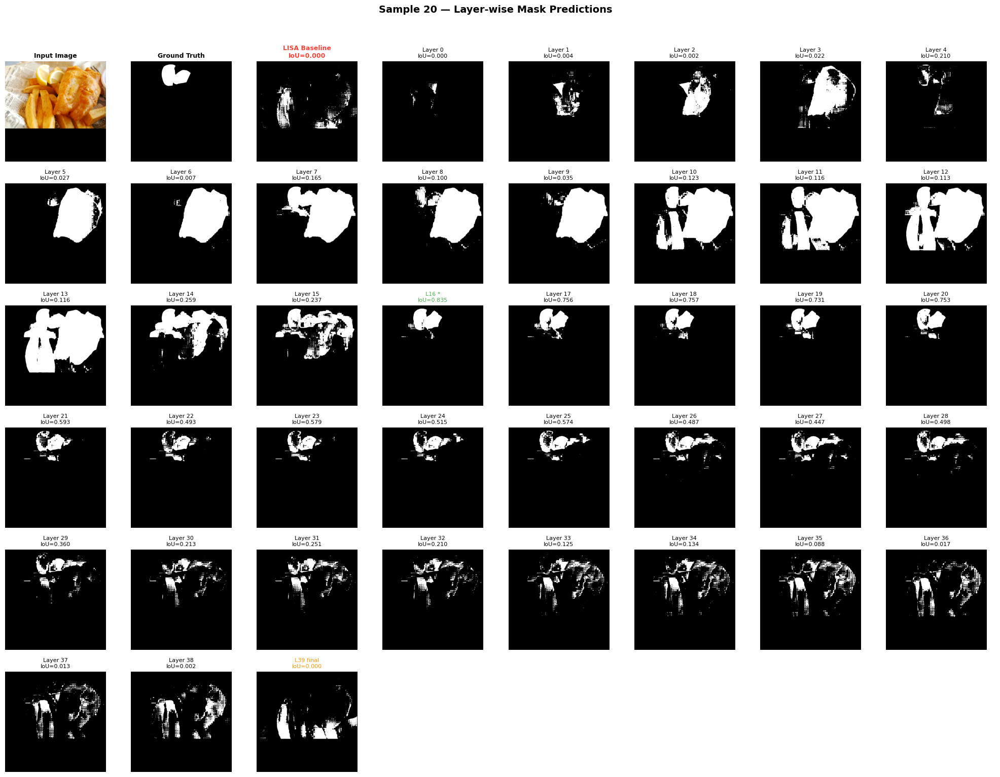


Analyzing Sample 21
  Prompt: A chat between a curious human and an artificial intelligence assistant. The ass...
  Number of layers: 40
  LISA baseline IoU: 0.1959
  Final layer IoU:   0.2230
  Best layer: 10 with IoU=0.9530


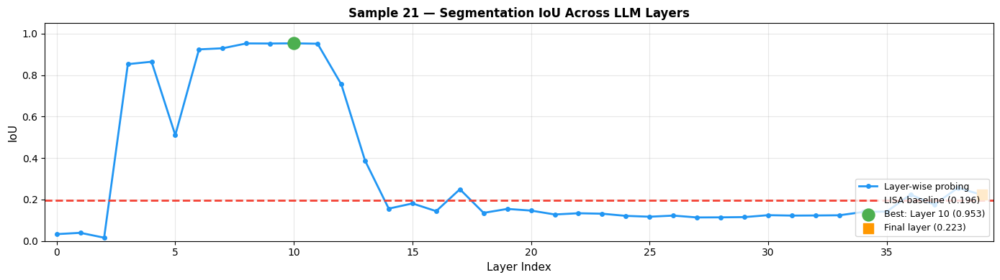

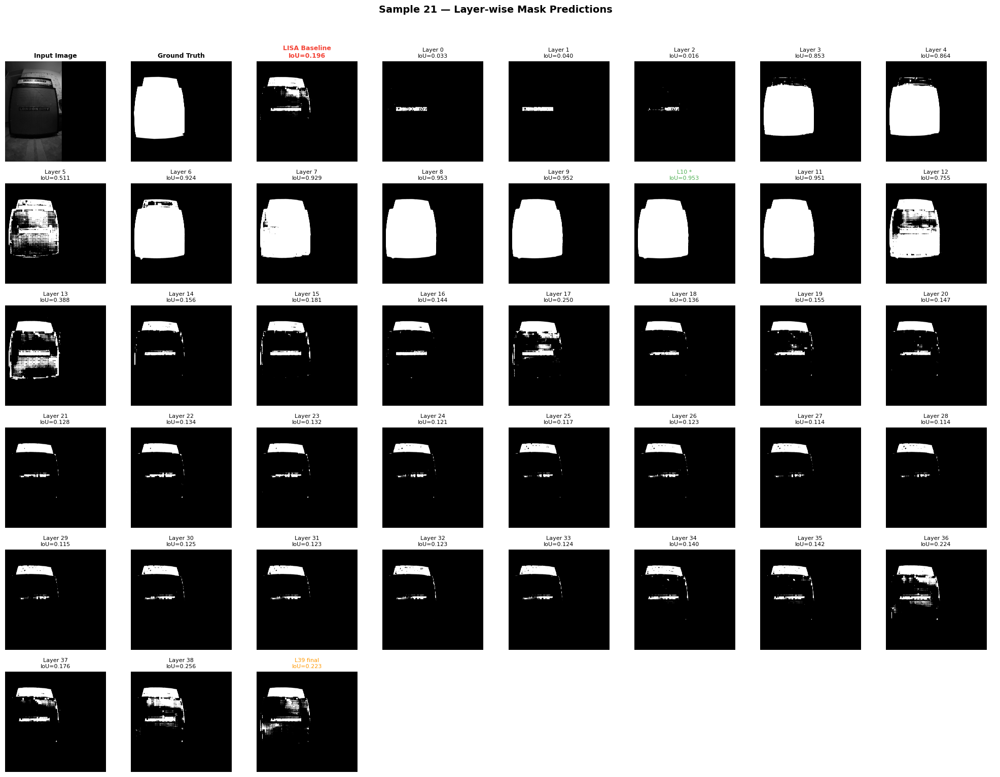

In [38]:
sample_ids = [10, 20, 21] # Modify as needed

for idx in sample_ids:
    print(f"\n{'=' * 60}")
    print(f"Analyzing Sample {idx}")
    print(f"{'=' * 60}")

    res = probe_layers_seg(test_dataset, idx, save_all_masks=True)

    if res is None:
        continue

    gt_mask = res["gt_mask"]
    image_path = res["image_path"]
    image_np = cv2.imread(image_path)[..., ::-1]

    base_iou, base_mask = baseline_iou_seg(test_dataset, idx, gt_mask)

    ious = res["ious"]
    print(f"  Prompt: {res['conversations'][0][:80]}...")
    print(f"  Number of layers: {res['num_layers']}")
    print(f"  LISA baseline IoU: {base_iou:.4f}")
    print(f"  Final layer IoU:   {ious[-1]:.4f}")
    print(f"  Best layer: {np.argmax(ious)} with IoU={max(ious):.4f}")

    fig1, ax1 = plt.subplots(figsize=(14, 4))
    draw_iou_curve(ious, base_iou, idx, ax=ax1)
    plt.tight_layout()
    plt.show()

    fig2 = draw_masks_grid(res, image_np, gt_mask, base_mask, base_iou, idx)
    plt.show()


In [39]:
print(

SyntaxError: incomplete input (149104261.py, line 1)

### 7. Geometry of the `[SEG]` Embedding Space

**Paper reference:** *Meng et al., "Locating and Editing Factual Associations in GPT", NeurIPS 2022.*

Meng et al. introduced *causal tracing* — surgically modifying hidden representations and measuring the downstream effect — to localise where factual knowledge is stored in LLMs.
Applied to LISA, we can probe the **geometry of the 256-d `[SEG]` embedding space** that bridges the LLM and SAM:

* If two prompts targeting *different* objects on the same image yield embeddings **A** and **B**, does linearly interpolating between them produce masks that smoothly morph from object A to object B?

**Task.**
1. Select an image with two distinct objects. Run LISA with two different prompts → embeddings **A** and **B**.
2. Compute 7 linear interpolations: α ∈ {0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0}.
3. Decode each interpolated embedding through SAM and visualise the mask sequence.

In [40]:
# TODO: Add here helper functions if needed
# ...

@torch.no_grad()
def get_seg_emb_256(prompt, image_path, params=PARAMETERS):
    batch = make_batch_lisa(prompt, image_path, params=params, add_seg=True)

    out_ids, _ = model.evaluate(
        batch["image_clip"],
        batch["image_sam"],
        batch["input_ids"],
        batch["resize_list"],
        batch["orig_list"],
        max_new_tokens=params["max_new_tokens"],
        tokenizer=tokenizer,
    )

    full_ids = out_ids

    out = model(
        input_ids=full_ids,
        images=batch["image_clip"],
        attention_mask=torch.ones_like(full_ids),
        past_key_values=None,
        output_hidden_states=True,
        return_dict=True,
    )

    last_h = out.hidden_states[-1]
    seg_pos_all = (full_ids[0] == seg_token_idx).nonzero(as_tuple=True)[0]
    if len(seg_pos_all) == 0:
        return None, batch

    seg_pos = seg_pos_all[-1].item()

    if last_h.dim() == 3:
        seg_h = last_h[0, seg_pos].unsqueeze(0)
    else:
        seg_h = last_h[seg_pos].unsqueeze(0)

    proj = get_proj_mlp(model)
    emb_256 = proj(seg_h.to(torch_dtype))
    return emb_256.detach(), batch


@torch.no_grad()
def run_interp_exp(dataset, idx, text_a, text_b, n_steps=7):
    item = dataset[idx]
    image_path = item[0]
    gt_mask = item[4]
    ds_text = item[3]

    if isinstance(ds_text, (list, tuple)):
        ds_text = ds_text[0]

    emb_a, batch_a = get_seg_emb_256(text_a, image_path, params=PARAMETERS)
    emb_b, batch_b = get_seg_emb_256(text_b, image_path, params=PARAMETERS)

    if emb_a is None:
        print(f"Sample {idx}: prompt A produced no [SEG] token: {text_a}")
        return None
    if emb_b is None:
        print(f"Sample {idx}: prompt B produced no [SEG] token: {text_b}")
        return None

    image_embs = model.get_visual_embs(batch_a["image_sam"])

    alpha_list = np.linspace(0, 1, n_steps)
    mask_list = []

    for a in alpha_list:
        emb_mix = (1 - a) * emb_a + a * emb_b

        mask_logits = decode_emb_to_mask(
            emb_mix,
            image_embs,
            batch_a["resize_list"][0],
            batch_a["orig_list"][0],
        )

        mask_bool = mask_logits.detach().cpu().numpy() > 0
        mask_list.append(mask_bool)

    return {
        "alphas": alpha_list,
        "interp_masks": mask_list,
        "image_path": image_path,
        "gt_mask": to_np2d(gt_mask) == 1,
        "prompt_a": text_a,
        "prompt_b": text_b,
        "dataset_prompt": ds_text,
    }


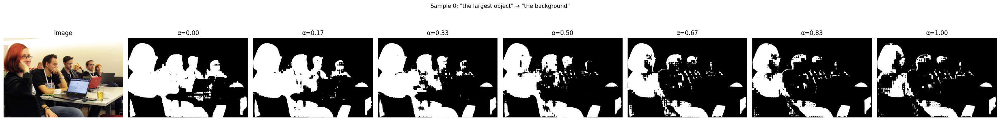

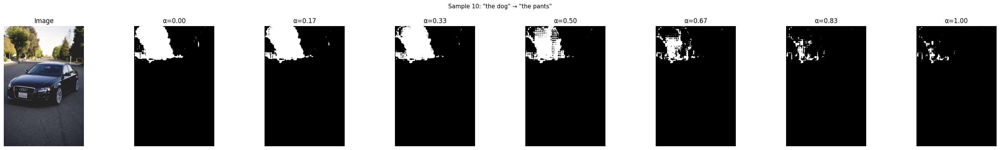

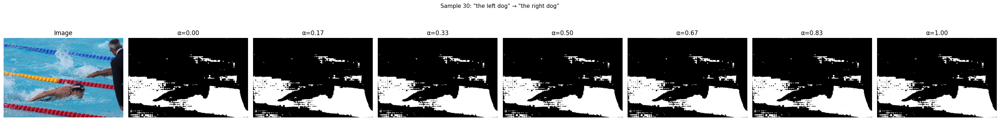

In [41]:
exp_list = [
    (0, "the largest object", "the background"),
    (10, "the dog", "the pants"),
    (30, "the left dog", "the right dog"),
]

for idx, text_a, text_b in exp_list:
    res = run_interp_exp(train_dataset, idx, text_a, text_b, n_steps=7)
    if res is None:
        continue

    n = len(res["alphas"]) + 1
    fig, axs = plt.subplots(1, n, figsize=(3.5 * n, 4))

    axs[0].imshow(cv2.imread(res["image_path"])[..., ::-1])
    axs[0].set_title("Image")
    axs[0].axis("off")

    for j, (a, m) in enumerate(zip(res["alphas"], res["interp_masks"])):
        mm = to_np2d(m)
        axs[j + 1].imshow(mm, cmap="gray")
        axs[j + 1].set_title(f"α={a:.2f}")
        axs[j + 1].axis("off")

    fig.suptitle(f'Sample {idx}: "{text_a}" → "{text_b}"', fontsize=11)
    plt.tight_layout()
    plt.show()
